## 1. Hugging Face Login

#### This imports the token from Kaggle Secrets, so make sure the secret is set correctly before running the code.

In [1]:
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF_TOKEN")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [2]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))


def get_device():
    """
      Return the computing device used in the current session.
    """
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


DEVICE = get_device()
print("Using device:", DEVICE)
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0))


CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4
Using device: cuda
Tesla T4


In [3]:
# shutil.rmtree("/kaggle/working/cjpe_runs_fast")

## 4. Load Tokenizer

In [5]:
# %%writefile a1_tokenizer.py
"""Expose your Assignment-1 BPE implementation to Assignment 3.

Reuse your A-1 tokenizer code/class here. The important change is that it must be
RETRAINED on the `train_text` supplied by Assignment 3 rather than reusing a tokenizer
trained on the Assignment-1 dataset.
"""

''' Required returned interface:
      tokenizer.encode(text) -> sequence of integer ids
      tokenizer.decode(ids) -> string
      tokenizer.vocab_size OR tokenizer.get_vocab_size()'''
import re
from tqdm import tqdm
from collections import defaultdict, Counter

class ByteLevelBPE:
    def __init__(self, vocab_size=5000):
        self.vocab_size = vocab_size
        self.reserved = ["<pad>", "<unk>", "<s>", "</s>"]
        self.merges = []
        self.itos = list(self.reserved)
        self.stoi = {}
        self.ranks = {}
        self.merged_map = {}
        self._cache = {}
        # Regex pattern matching words, numbers, individual punctuation, and whitespace sequences
        pattern = r"""'s|'t|'re|'ve|'m|'ll|'d| ?[^\s\W\d_]+| ?\d+| ?[^\s\w]+|\s+(?!\S)|\s+"""
        self.pat = re.compile(pattern, re.UNICODE)
        
    def _split_text(self, text):
        """Splits text into chunks preserving whitespace, or falls back to basic regex split."""
        pattern = r"""'s|'t|'re|'ve|'m|'ll|'d| ?[^\s\W\d_]+| ?\d+| ?[^\s\w]+|\s+(?!\S)|\s+"""
        return re.findall(pattern, str(text), flags=re.UNICODE)

    def fit(self, texts, max_unique_words=200000):
        """Train a byte-level BPE tokenizer using inverted indexing for fast merging."""
        raw_counts = Counter()
        iterator = [texts] if isinstance(texts, str) else texts

        # Preserve whitespace tokens when populating initial raw_counts
        for text in tqdm(iterator, desc="Building word vocabulary"):
            for chunk in self._split_text(text):
                raw_counts[chunk] += 1

        if max_unique_words and len(raw_counts) > max_unique_words:
            most_common = raw_counts.most_common(max_unique_words)
            raw_counts = dict(most_common)

        word_freqs = {}
        pair_counts = defaultdict(int)
        pair_to_words = defaultdict(set)

        for word, count in raw_counts.items():
            encoded = word.encode("utf-8")
            byte_word = tuple(encoded[i:i+1] for i in range(len(encoded)))
            word_freqs[byte_word] = count

            for i in range(len(byte_word) - 1):
                pair = (byte_word[i], byte_word[i + 1])
                pair_counts[pair] += count
                pair_to_words[pair].add(byte_word)

        base_bytes = sorted({token for word in word_freqs for token in word})
        self.itos = list(self.reserved) + base_bytes
        self.merges = []

        target_merges = self.vocab_size - len(self.itos)

        with tqdm(total=target_merges, desc="Training BPE Merges") as pbar:
            while len(self.itos) < self.vocab_size:
                if not pair_counts:
                    break

                best_pair = max(pair_counts, key=lambda p: (pair_counts[p], p[0], p[1]))
                if pair_counts[best_pair] <= 0:
                    break

                merged_token = best_pair[0] + best_pair[1]
                self.merges.append((best_pair, merged_token))
                self.itos.append(merged_token)

                words_to_update = list(pair_to_words[best_pair])
                del pair_counts[best_pair]
                del pair_to_words[best_pair]

                p0, p1 = best_pair

                for word in words_to_update:
                    count = word_freqs.get(word, 0)
                    if count == 0:
                        continue

                    new_word = []
                    i = 0
                    n = len(word)

                    while i < n:
                        if i + 1 < n and word[i] == p0 and word[i + 1] == p1:
                            new_word.append(merged_token)
                            i += 2
                        else:
                            new_word.append(word[i])
                            i += 1

                    new_word = tuple(new_word)

                    for j in range(len(word) - 1):
                        old_p = (word[j], word[j + 1])
                        if old_p in pair_counts:
                            pair_counts[old_p] -= count
                            if pair_counts[old_p] <= 0:
                                del pair_counts[old_p]

                    for j in range(len(new_word) - 1):
                        new_p = (new_word[j], new_word[j + 1])
                        pair_counts[new_p] += count
                        pair_to_words[new_p].add(new_word)

                    del word_freqs[word]
                    word_freqs[new_word] = count

                pbar.update(1)

        self.vocab_size = len(self.itos)
        self.stoi = {token: idx for idx, token in enumerate(self.itos)}
        self.ranks = {pair: rank for rank, (pair, _) in enumerate(self.merges)}
        self.merged_map = {pair: merged for pair, merged in self.merges}
        self._cache = {}
        return self

    def encode_word(self, word):
        """Encode single word using memoization and local pair updates."""
        if word in self._cache:
            return self._cache[word]

        encoded = word.encode("utf-8")
        tokens = [encoded[i:i+1] for i in range(len(encoded))]

        if len(tokens) <= 1:
            res = [self.stoi.get(token, self.stoi["<unk>"]) for token in tokens]
            self._cache[word] = res
            return res

        while len(tokens) > 1:
            min_rank = float("inf")
            min_pair = None

            for i in range(len(tokens) - 1):
                pair = (tokens[i], tokens[i + 1])
                rank = self.ranks.get(pair, float("inf"))
                if rank < min_rank:
                    min_rank = rank
                    min_pair = pair

            if min_pair is None or min_rank == float("inf"):
                break

            merged = self.merged_map[min_pair]
            new_tokens = []
            i = 0
            n = len(tokens)
            p0, p1 = min_pair

            while i < n:
                if i + 1 < n and tokens[i] == p0 and tokens[i + 1] == p1:
                    new_tokens.append(merged)
                    i += 2
                else:
                    new_tokens.append(tokens[i])
                    i += 1
            tokens = new_tokens

        res = [self.stoi.get(token, self.stoi["<unk>"]) for token in tokens]
        self._cache[word] = res
        return res

    def encode(self, text):
        """Encode a sentence while preserving original spaces and newlines."""
        ids = [self.stoi["<s>"]]
        for chunk in self._split_text(text):
            ids.extend(self.encode_word(chunk))
        ids.append(self.stoi["</s>"])
        return ids

    def decode(self, ids):
        """Decode BPE token IDs back into text seamlessly."""
        byte_list = []
        for idx in ids:
            if 0 <= idx < len(self.itos):
                tok = self.itos[idx]
            else:
                tok = "<unk>"
            if tok not in self.reserved and isinstance(tok, bytes):
                byte_list.append(tok)
        try:
            return b"".join(byte_list).decode("utf-8", errors="ignore")
        except Exception:
            return ""

    def get_vocab_size(self):
        return self.vocab_size

def train_tokenizer(train_text: str, vocab_size: int):
    """Train A-1 BPE tokenizer on `train_text` and return the trained tokenizer."""
    tokenizer = ByteLevelBPE(vocab_size)
    tokenizer.fit(train_text)
    return tokenizer

## 9. Define The Model

## LMConfig

In [6]:
@dataclass
class LMConfig:
    # ---- general ----
    vocab_size: int = VOCAB_SIZE
    max_seq_len: int = MODEL_CONTEXT_LENGTH
    d_model: int = N_EMBD
    n_layers: int = N_LAYER
    dropout: float = 0.0
    bias: bool = False
    tie_embeddings: bool = True
    norm_type: str = "rmsnorm"          # "rmsnorm" | "layernorm"
    norm_eps: float = 1e-6

    # ---- positional ----
    pos_emb_type: str = "rope"          # "rope" | "sinusoidal"
    rope_theta: float = 10000.0

    # ---- attention ----
    attn_type: str = "gqa"              # "gqa" | "mla"
    n_heads: int = N_HEAD
    # GQA (n_kv_heads == n_heads -> MHA, 1 -> MQA)
    n_kv_heads: int = 2
    head_dim: Optional[int] = None      # defaults to d_model // n_heads
    # MLA
    q_lora_rank: Optional[int] = 256    # None -> no query compression
    kv_lora_rank: int = 128
    qk_nope_head_dim: int = 48
    qk_rope_head_dim: int = 16
    v_head_dim: int = 64

    # ---- feed-forward ----
    ffn_type: str = "dense"             # "dense" | "moe"
    d_ff: int = 2048
    # MoE
    n_experts: int = 8
    top_k: int = 2
    n_shared_experts: int = 1
    expert_d_ff: int = 512
    aux_loss_coef: float = 0.01
    first_k_dense_layers: int = 0       # first k layers stay dense
    moe_layer_freq: int = 1             # after that, every n-th layer is MoE

    def __post_init__(self):
        assert self.norm_type in ("rmsnorm", "layernorm")
        assert self.pos_emb_type in ("rope", "sinusoidal")
        assert self.attn_type in ("gqa", "mla")
        assert self.ffn_type in ("dense", "moe")

        if self.pos_emb_type == "sinusoidal":
            assert self.d_model % 2 == 0, "sinusoidal needs even d_model"

        if self.attn_type == "gqa":
            if self.head_dim is None:
                assert self.d_model % self.n_heads == 0, "d_model must be divisible by n_heads"
                self.head_dim = self.d_model // self.n_heads
            assert self.n_heads % self.n_kv_heads == 0, "n_heads must be divisible by n_kv_heads"
            if self.pos_emb_type == "rope":
                assert self.head_dim % 2 == 0, "RoPE needs even head_dim"
        else:
            if self.pos_emb_type == "rope":
                assert self.qk_rope_head_dim % 2 == 0 and self.qk_rope_head_dim > 0

        if self.ffn_type == "moe":
            assert 1 <= self.top_k <= self.n_experts

    @property
    def rope_dim(self) -> int:
        return self.qk_rope_head_dim if self.attn_type == "mla" else self.head_dim

    def is_moe_layer(self, layer_idx: int) -> bool:
        if self.ffn_type != "moe" or layer_idx < self.first_k_dense_layers:
            return False
        return (layer_idx - self.first_k_dense_layers) % self.moe_layer_freq == 0

## Normalization layers

In [7]:
class RMSNorm(nn.Module):
    def __init__(self, dim: int, eps: float = 1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        dtype = x.dtype
        x = x.float()
        x = x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)
        return (x * self.weight.float()).to(dtype)


def make_norm(cfg: LMConfig, dim: int) -> nn.Module:
    if cfg.norm_type == "rmsnorm":
        return RMSNorm(dim, cfg.norm_eps)
    return nn.LayerNorm(dim, eps=cfg.norm_eps)

## Positional embeddings (RoPE and sinusoidal)

In [8]:
class RoPE(nn.Module):
    """Rotary embedding. Rotates q and k of shape (B, H, T, dim)."""

    def __init__(self, dim: int, max_seq_len: int, theta: float = 10000.0):
        super().__init__()
        inv_freq = 1.0 / (theta ** (torch.arange(0, dim, 2).float() / dim))
        t = torch.arange(max_seq_len).float()
        freqs = torch.outer(t, inv_freq)               # (L, dim/2)
        emb = torch.cat([freqs, freqs], dim=-1)        # (L, dim)
        self.register_buffer("cos", emb.cos(), persistent=False)
        self.register_buffer("sin", emb.sin(), persistent=False)

    @staticmethod
    def _rotate_half(x):
        x1, x2 = x.chunk(2, dim=-1)
        return torch.cat([-x2, x1], dim=-1)

    def rotate(self, x, positions):
        cos, sin = self.cos[positions], self.sin[positions]
        if cos.dim() == 2:                              # positions: (T,)
            cos, sin = cos[None, None], sin[None, None]
        else:                                           # positions: (B, T)
            cos, sin = cos[:, None], sin[:, None]
        cos, sin = cos.to(x.dtype), sin.to(x.dtype)
        return x * cos + self._rotate_half(x) * sin

    def forward(self, q, k, positions):
        return self.rotate(q, positions), self.rotate(k, positions)


class SinusoidalPositionalEmbedding(nn.Module):
    """Fixed sin/cos table, added to token embeddings once at model level."""

    def __init__(self, d_model: int, max_seq_len: int):
        super().__init__()
        pos = torch.arange(max_seq_len).float().unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_seq_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe, persistent=False)

    def forward(self, x, offset: int = 0):
        T = x.size(1)
        return x + self.pe[offset:offset + T].to(x.dtype)

## Attention helper and GQA

In [9]:
def causal_sdpa(q, k, v, dropout_p: float = 0.0, training: bool = False):
    """Causal attention that also works when k/v are longer than q (KV cache)."""
    Tq, Tk = q.size(2), k.size(2)
    p = dropout_p if training else 0.0
    if Tq == Tk:
        return F.scaled_dot_product_attention(q, k, v, dropout_p=p, is_causal=True)
    if Tq == 1:
        return F.scaled_dot_product_attention(q, k, v, dropout_p=p)
    mask = torch.ones(Tq, Tk, dtype=torch.bool, device=q.device).tril(diagonal=Tk - Tq)
    return F.scaled_dot_product_attention(q, k, v, attn_mask=mask, dropout_p=p)


def masked_sdpa(q, k, v, attn_mask, dropout_p=0.0, training=False):
    if attn_mask is None:
        return causal_sdpa(q, k, v, dropout_p, training)            # training path unchanged
    return F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask,
                                          dropout_p=dropout_p if training else 0.0)

class GQAttention(nn.Module):
    """Grouped-query attention. cache = (k, v), each (B, n_kv_heads, T, head_dim)."""

    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.n_heads, self.n_kv, self.hd = cfg.n_heads, cfg.n_kv_heads, cfg.head_dim
        self.q_proj = nn.Linear(cfg.d_model, self.n_heads * self.hd, bias=cfg.bias)
        self.k_proj = nn.Linear(cfg.d_model, self.n_kv * self.hd, bias=cfg.bias)
        self.v_proj = nn.Linear(cfg.d_model, self.n_kv * self.hd, bias=cfg.bias)
        self.o_proj = nn.Linear(self.n_heads * self.hd, cfg.d_model, bias=cfg.bias)
        self.dropout = cfg.dropout

    def forward(self, x, rope=None, positions=None, kv_cache=None, attn_mask=None):
        B, T, _ = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.hd).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_kv, self.hd).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_kv, self.hd).transpose(1, 2)
        if rope is not None:
            q, k = rope(q, k, positions)
        if kv_cache is not None:
            k = torch.cat([kv_cache[0], k], dim=2)
            v = torch.cat([kv_cache[1], v], dim=2)
        new_cache = (k, v)
        rep = self.n_heads // self.n_kv
        out = masked_sdpa(q, k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1),
                          attn_mask, self.dropout, self.training)
        out = out.transpose(1, 2).reshape(B, T, self.n_heads * self.hd)
        return self.o_proj(out), new_cache

## MLA

In [10]:
class MLAttention(nn.Module):
    """
    Multi-head Latent Attention (DeepSeek-style, un-absorbed version).
    cache = (latent (B, 1, T, kv_lora_rank), k_rope (B, 1, T, rope_dim) or None).
    Only the compressed latent and the small shared k_rope are cached.
    With sinusoidal positions the decoupled RoPE part is dropped (rope_dim = 0).
    """

    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.H = cfg.n_heads
        self.dn = cfg.qk_nope_head_dim
        self.dr = cfg.qk_rope_head_dim if cfg.pos_emb_type == "rope" else 0
        self.dv = cfg.v_head_dim
        self.dropout = cfg.dropout

        q_out = self.H * (self.dn + self.dr)
        if cfg.q_lora_rank:
            self.q_down = nn.Linear(cfg.d_model, cfg.q_lora_rank, bias=cfg.bias)
            self.q_norm = make_norm(cfg, cfg.q_lora_rank)
            self.q_up = nn.Linear(cfg.q_lora_rank, q_out, bias=False)
            self.q_proj = None
        else:
            self.q_proj = nn.Linear(cfg.d_model, q_out, bias=cfg.bias)

        self.kv_down = nn.Linear(cfg.d_model, cfg.kv_lora_rank, bias=cfg.bias)
        self.kv_norm = make_norm(cfg, cfg.kv_lora_rank)
        self.kv_up = nn.Linear(cfg.kv_lora_rank, self.H * (self.dn + self.dv), bias=False)
        self.k_rope_proj = nn.Linear(cfg.d_model, self.dr, bias=cfg.bias) if self.dr > 0 else None
        self.o_proj = nn.Linear(self.H * self.dv, cfg.d_model, bias=cfg.bias)

    def forward(self, x, rope=None, positions=None, kv_cache=None, attn_mask=None):
        B, T, _ = x.shape
        q = self.q_up(self.q_norm(self.q_down(x))) if self.q_proj is None else self.q_proj(x)
        q = q.view(B, T, self.H, self.dn + self.dr).transpose(1, 2)
        latent = self.kv_norm(self.kv_down(x)).unsqueeze(1)
        k_rope = None
        if self.dr > 0:
            q_nope, q_rope = q.split([self.dn, self.dr], dim=-1)
            k_rope = self.k_rope_proj(x).unsqueeze(1)
            q_rope, k_rope = rope(q_rope, k_rope, positions)
        else:
            q_nope = q
        if kv_cache is not None:
            latent = torch.cat([kv_cache[0], latent], dim=2)
            if k_rope is not None:
                k_rope = torch.cat([kv_cache[1], k_rope], dim=2)
        new_cache = (latent, k_rope)
        Tk = latent.size(2)
        kv = self.kv_up(latent.squeeze(1)).view(B, Tk, self.H, self.dn + self.dv).transpose(1, 2)
        k_nope, v = kv.split([self.dn, self.dv], dim=-1)
        if self.dr > 0:
            q_full = torch.cat([q_nope, q_rope], dim=-1)
            k_full = torch.cat([k_nope, k_rope.expand(-1, self.H, -1, -1)], dim=-1)
        else:
            q_full, k_full = q_nope, k_nope
        out = masked_sdpa(q_full, k_full, v, attn_mask, self.dropout, self.training)
        out = out.transpose(1, 2).reshape(B, T, self.H * self.dv)
        return self.o_proj(out), new_cache


ATTN_REGISTRY = {"gqa": GQAttention, "mla": MLAttention}

## Feed-forward networks (GeLU)

In [11]:
class DenseFFN(nn.Module):
    """Linear -> GeLU -> Linear. Returns (out, aux_loss=0)."""

    def __init__(self, cfg: LMConfig, d_ff: Optional[int] = None):
        super().__init__()
        d_ff = d_ff or cfg.d_ff
        self.fc1 = nn.Linear(cfg.d_model, d_ff, bias=cfg.bias)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(d_ff, cfg.d_model, bias=cfg.bias)

    def forward(self, x):
        return self.fc2(self.act(self.fc1(x))), x.new_zeros(())


class MoEFFN(nn.Module):
    """Top-k routed experts (DenseFFN each) + optional always-on shared experts."""

    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.E, self.k = cfg.n_experts, cfg.top_k
        self.router = nn.Linear(cfg.d_model, self.E, bias=False)
        self.experts = nn.ModuleList([DenseFFN(cfg, cfg.expert_d_ff) for _ in range(self.E)])
        self.shared = nn.ModuleList([DenseFFN(cfg, cfg.expert_d_ff) for _ in range(cfg.n_shared_experts)])

    def forward(self, x):
        B, T, D = x.shape
        flat = x.reshape(-1, D)                                  # (N, D)

        probs = self.router(flat).float().softmax(dim=-1)        # (N, E)
        topv, topi = probs.topk(self.k, dim=-1)                  # (N, k)
        topv = topv / topv.sum(dim=-1, keepdim=True)             # renormalise

        out = torch.zeros_like(flat)
        for e, expert in enumerate(self.experts):
            tok_idx, slot = (topi == e).nonzero(as_tuple=True)
            if tok_idx.numel() == 0:
                continue
            y, _ = expert(flat[tok_idx])
            w = topv[tok_idx, slot].unsqueeze(-1).to(y.dtype)
            out.index_add_(0, tok_idx, (y * w).to(out.dtype))

        for sh in self.shared:
            out = out + sh(flat)[0]

        # Switch-style load-balancing loss: E * sum_i f_i * P_i
        if self.training:
            f = F.one_hot(topi, self.E).sum(dim=1).float().mean(dim=0) / self.k
            P = probs.mean(dim=0)
            aux = self.E * (f * P).sum()
        else:
            aux = x.new_zeros(())
        return out.view(B, T, D), aux


FFN_REGISTRY = {"dense": DenseFFN, "moe": MoEFFN}

## TransformerBlock

In [12]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg: LMConfig, layer_idx: int):
        super().__init__()
        self.norm1 = make_norm(cfg, cfg.d_model)
        self.attn = ATTN_REGISTRY[cfg.attn_type](cfg)
        self.norm2 = make_norm(cfg, cfg.d_model)
        self.ffn = FFN_REGISTRY["moe" if cfg.is_moe_layer(layer_idx) else "dense"](cfg)
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x, rope=None, positions=None, kv_cache=None, attn_mask=None):
        a, new_cache = self.attn(self.norm1(x), rope, positions, kv_cache, attn_mask)
        x = x + self.drop(a)
        f, aux = self.ffn(self.norm2(x))
        x = x + self.drop(f)
        return x, aux, new_cache

## DecoderLM

In [13]:
class DecoderLM(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.sin_emb = (SinusoidalPositionalEmbedding(cfg.d_model, cfg.max_seq_len)
                        if cfg.pos_emb_type == "sinusoidal" else None)
        self.rope = (RoPE(cfg.rope_dim, cfg.max_seq_len, cfg.rope_theta)
                     if cfg.pos_emb_type == "rope" else None)
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([TransformerBlock(cfg, i) for i in range(cfg.n_layers)])
        self.final_norm = make_norm(cfg, cfg.d_model)
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        if cfg.tie_embeddings:
            self.lm_head.weight = self.tok_emb.weight

        self.apply(self._init_weights)
        # scaled init on residual output projections
        for name, p in self.named_parameters():
            if name.endswith("o_proj.weight") or name.endswith("fc2.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layers))

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def forward(self, input_ids, targets=None, kv_caches=None, use_cache=False,
                last_only=False, attention_mask=None):
        B, T = input_ids.shape
        past = 0 if kv_caches is None else kv_caches[0][0].size(2)
        dev = input_ids.device
        if attention_mask is None:                                      # training / unpadded: unchanged behaviour
            assert past + T <= self.cfg.max_seq_len, "sequence exceeds max_seq_len"
            positions = torch.arange(past, past + T, device=dev)        # (T,)
            attn_mask = None
        else:
            am = attention_mask.to(dev).bool()
            assert am.shape == (B, past + T), f"attention_mask must be (B, past+T) = {(B, past + T)}"
            positions = (am.long().cumsum(-1) - 1).clamp(min=0)[:, past:]            # (B, T) per-row positions
            q_idx = torch.arange(past, past + T, device=dev)[:, None]
            k_idx = torch.arange(past + T, device=dev)[None, :]
            # causal AND key is a real token; the diagonal is always allowed so padded query rows never become all -inf
            attn_mask = ((k_idx <= q_idx)[None, None] & am[:, None, None, :]) | (k_idx == q_idx)[None, None]
    
        x = self.tok_emb(input_ids)
        if self.sin_emb is not None:
            x = x * math.sqrt(self.cfg.d_model) + self.sin_emb.pe[positions].to(x.dtype)
        x = self.drop(x)
    
        aux_total = x.new_zeros(())
        new_caches = []
        for i, block in enumerate(self.blocks):
            cache_i = None if kv_caches is None else kv_caches[i]
            x, aux, new_cache = block(x, self.rope, positions, cache_i, attn_mask)
            aux_total = aux_total + aux
            new_caches.append(new_cache)
    
        x = self.final_norm(x)
        if last_only:
            x = x[:, -1:, :]
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            ce = F.cross_entropy(logits.reshape(-1, logits.size(-1)).float(), targets.reshape(-1), ignore_index=-100)
            loss = ce + self.cfg.aux_loss_coef * aux_total
        caches = new_caches if (use_cache or kv_caches is not None) else None
        return logits, loss, caches

    @torch.no_grad()
    def generate(self, input_ids, attention_mask=None, max_new_tokens=400, temperature=0.4, top_k=50, top_p=0.9,
                 repetition_penalty=1.1, rep_window=256, no_repeat_ngram=0, ban_ids=(), pad_id=0, 
                 tokenizer=None, target_words=None, check_every=16):
        """input_ids: (B, L) LEFT-padded; attention_mask: (B, L) with 1 for real tokens, 0 for padding."""
        was_training = self.training
        self.eval()
        B, L = input_ids.shape
        dev = input_ids.device
        attn = (torch.ones(B, L, dtype=torch.long, device=dev) if attention_mask is None
                else attention_mask.to(dev).long())
        assert int(attn.sum(1).max()) + max_new_tokens <= self.cfg.max_seq_len, \
            "longest prompt + new tokens exceed max_seq_len"
        ban = torch.tensor(sorted(set(ban_ids)), dtype=torch.long, device=dev) if len(ban_ids) else None
    
        n = no_repeat_ngram
        seen = [dict() for _ in range(B)]
        hist = [[] for _ in range(B)]
    
        gen = input_ids.new_zeros((B, 0))
        done = torch.zeros(B, dtype=torch.bool, device=dev)
        caches, cur = None, input_ids
        for step in range(max_new_tokens):
            logits, _, caches = self(cur, kv_caches=caches, use_cache=True, last_only=True, attention_mask=attn)
            logits = logits[:, -1, :].float()
            if ban is not None:
                logits[:, ban] = float("-inf")
            if repetition_penalty != 1.0 and gen.size(1) > 0:
                recent = gen[:, -rep_window:]
                sc = torch.gather(logits, 1, recent)
                sc = torch.where(sc > 0, sc / repetition_penalty, sc * repetition_penalty)
                logits.scatter_(1, recent, sc)
            if n > 1:
                for b in range(B):
                    if len(hist[b]) >= n - 1:
                        banned = seen[b].get(tuple(hist[b][-(n - 1):]))
                        if banned:
                            logits[b, list(banned)] = float("-inf")
    
            if temperature <= 0:
                nxt = logits.argmax(dim=-1, keepdim=True)
            else:
                logits = logits / temperature
                if top_k:
                    kth = torch.topk(logits, min(top_k, logits.size(-1))).values[:, -1, None]
                    logits = logits.masked_fill(logits < kth, float("-inf"))
                if top_p and top_p < 1.0:
                    sl, si = torch.sort(logits, descending=True, dim=-1)
                    pr = torch.softmax(sl, dim=-1)
                    sl = sl.masked_fill(pr.cumsum(-1) - pr > top_p, float("-inf"))
                    logits = torch.full_like(logits, float("-inf")).scatter(1, si, sl)
                nxt = torch.multinomial(torch.softmax(logits, dim=-1), 1)
    
            nxt = torch.where(done.unsqueeze(1), torch.full_like(nxt, pad_id), nxt)
            if n > 1:
                for b, t in enumerate(nxt.squeeze(1).tolist()):
                    h = hist[b]
                    if len(h) >= n - 1:
                        seen[b].setdefault(tuple(h[-(n - 1):]), set()).add(t)
                    h.append(t)
            gen = torch.cat([gen, nxt], dim=1)
            cur = nxt
            attn = torch.cat([attn, torch.ones(B, 1, dtype=attn.dtype, device=dev)], dim=1)   # new token is a real token
    
            if target_words is not None and (step + 1) % check_every == 0:
                for b in torch.nonzero(~done).flatten().tolist():
                    if len(tokenizer.decode(gen[b].tolist()).split()) > target_words:
                        done[b] = True
                if done.all():
                    break
        self.train(was_training)
        return torch.cat([input_ids, gen], dim=1)

# Phase 5

In [35]:
# import shutil
# shutil.rmtree("/kaggle/working/lsi_runs/ckpt")

In [15]:
# !cp -rv ../input/datasets/pritam0289/phase1-models ./ 

'../input/datasets/pritam0289/phase1-models' -> './phase1-models'
'../input/datasets/pritam0289/phase1-models/best_models' -> './phase1-models/best_models'
'../input/datasets/pritam0289/phase1-models/best_models/best_models' -> './phase1-models/best_models/best_models'
'../input/datasets/pritam0289/phase1-models/best_models/best_models/abl_clean_gqa_rope_moe_best.pt' -> './phase1-models/best_models/best_models/abl_clean_gqa_rope_moe_best.pt'
'../input/datasets/pritam0289/phase1-models/best_models/best_models/abl_gqa_rope_moe_best.pt' -> './phase1-models/best_models/best_models/abl_gqa_rope_moe_best.pt'
'../input/datasets/pritam0289/phase1-models/best_models/best_models/abl_gqa_sin_moe_best.pt' -> './phase1-models/best_models/best_models/abl_gqa_sin_moe_best.pt'
'../input/datasets/pritam0289/phase1-models/best_models/best_models/abl_mla_rope_moe_best.pt' -> './phase1-models/best_models/best_models/abl_mla_rope_moe_best.pt'
'../input/datasets/pritam0289/phase1-models/best_models/best_mod

### Cell 1: Imports and config

In [36]:
import os, re, json, math, time, copy, random, pickle, zipfile, gc, contextlib, shutil
import multiprocessing as mp
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torch.utils.checkpoint import checkpoint
from huggingface_hub import hf_hub_download
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score

for need in ["LMConfig", "DecoderLM", "ByteLevelBPE", "MoEFFN"]:
    assert need in globals(), f"Run the Phase-1 cell that defines {need} first"

SEED = 42
def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
HF_TOKEN = globals().get("HF_TOKEN") or os.environ.get("HF_TOKEN")
PHASE1_DIR = "/kaggle/working/phase1-models"
CKPT_P1 = f"{PHASE1_DIR}/best_models/best_models"
OUT = "/kaggle/working/lsi_runs"
RES_DIR, PROB_DIR, CKPT_DIR, PLOT_DIR = [f"{OUT}/{d}" for d in ("res", "probs", "ckpt", "plots")]
for d in (OUT, RES_DIR, PROB_DIR, CKPT_DIR, PLOT_DIR): os.makedirs(d, exist_ok=True)

VARIANTS = ["clean_gqa_rope_moe", "mla_rope_moe", "gqa_sin_moe", "mla_sin_moe"]
BASE_VARIANT = "clean_gqa_rope_moe"       # architecture for ablations / technique study / KD
CHUNK = 512                          # tokens per chunk (incl. BOS)
HC = 12000                           # chars kept from head and from tail of each document
STUDENT_KEEP = [0, 5, 10, 15]        # KD student = these 4 of the 16 pretrained blocks
ADA_TARGET = 0.5
EFF_DOCS = 16                        # effective batch (documents)

# PROFILE controls compute. Start with "fast" as a dry run.
PROFILE = "full"                     # "fast" | "balanced" | "full"
PROF = dict(
    fast=dict(tech_docs=3000, abl_docs=1500, dev_docs=800, ep_tech=3, ep_abl=2),
    balanced=dict(tech_docs=10000, abl_docs=3000, dev_docs=None, ep_tech=3, ep_abl=2),
    full=dict(tech_docs=None, abl_docs=4000, dev_docs=None, ep_tech=2, ep_abl=2),
)[PROFILE]

def get_amp():
    if DEVICE.type != "cuda": return None, False
    return (torch.bfloat16, False) if torch.cuda.get_device_capability(0)[0] >= 8 else (torch.float16, True)
AMP_DTYPE, USE_SCALER = get_amp()
def amp(): return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None)

BASE = dict(vocab_size=30000, max_seq_len=2048, d_model=768, n_layers=16, n_heads=8, n_kv_heads=2,
            dropout=0.0, bias=False, tie_embeddings=True, d_ff=2048, q_lora_rank=384, kv_lora_rank=192,
            qk_nope_head_dim=80, qk_rope_head_dim=16, v_head_dim=96)
MOE = dict(ffn_type="moe", first_k_dense_layers=2, n_experts=8, top_k=2, n_shared_experts=1,
           expert_d_ff=512, aux_loss_coef=0.01)
CONFIGS = {
    "gqa_rope_moe": LMConfig(**BASE, **MOE, attn_type="gqa", pos_emb_type="rope"),
    "clean_gqa_rope_moe": LMConfig(**BASE, **MOE, attn_type="gqa", pos_emb_type="rope"),
    "mla_rope_moe": LMConfig(**BASE, **MOE, attn_type="mla", pos_emb_type="rope"),
    "gqa_sin_moe":  LMConfig(**BASE, **MOE, attn_type="gqa", pos_emb_type="sinusoidal"),
    "mla_sin_moe":  LMConfig(**BASE, **MOE, attn_type="mla", pos_emb_type="sinusoidal"),
}
if "tokenizer" not in globals() or not hasattr(tokenizer, "stoi"):
    with open(f"{PHASE1_DIR}/tokenizer.pkl", "rb") as f: tokenizer = pickle.load(f)
PAD, BOS = tokenizer.stoi["<pad>"], tokenizer.stoi["<s>"]

def load_phase1(variant):
    ck = torch.load(f"{CKPT_P1}/abl_{variant}_best.pt", map_location="cpu", weights_only=False)
    sd = ck["model"] if isinstance(ck, dict) and "model" in ck else ck
    lm = DecoderLM(CONFIGS[variant])
    lm.load_state_dict({k.replace("_orig_mod.", ""): v for k, v in sd.items()}, strict=True)
    return lm
print("device", DEVICE, "| amp", AMP_DTYPE, "| scaler", USE_SCALER, "| profile", PROFILE, PROF)

device cuda | amp torch.float16 | scaler True | profile full {'tech_docs': None, 'abl_docs': 4000, 'dev_docs': None, 'ep_tech': 2, 'ep_abl': 2}


### Cell 2: Load data and EDA

Phase_5_LSI/Train/train.json: reconstructing file:   0%|          |  0.00B /  299MB            

Phase_5_LSI/Train/train.json: downloading bytes:           |  0.00B            

Phase_5_LSI/Train/dev.json: reconstructing file:   0%|          |  0.00B / 79.4MB            

Phase_5_LSI/Train/dev.json: downloading bytes:           |  0.00B            

Phase_5_LSI/Test/test.json: reconstructing file:   0%|          |  0.00B / 98.1MB            

Phase_5_LSI/Test/test.json: downloading bytes:           |  0.00B            

42750 10181 13019
num labels L = 100 | labels never in train: 0


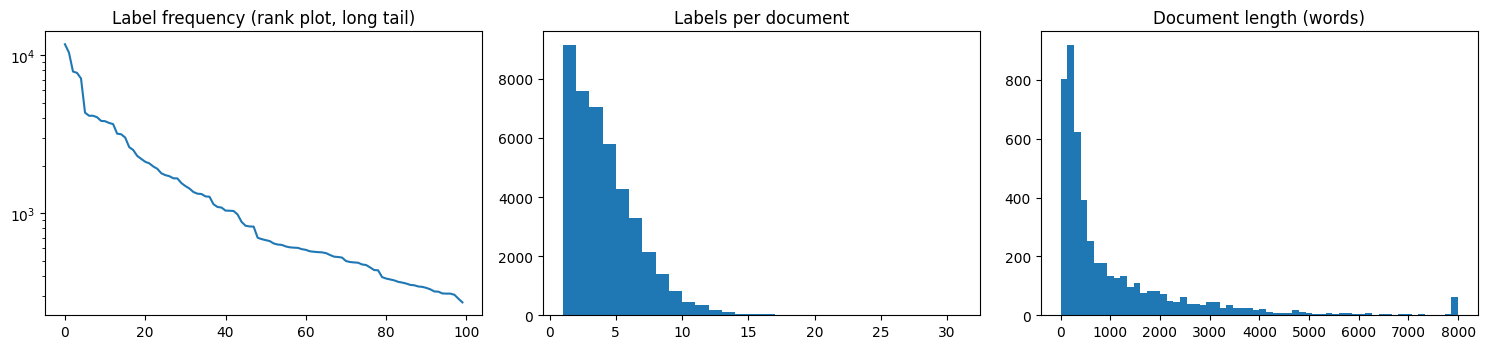

mean labels/doc 3.70 | single-label docs 21.39% | median words 446
labels with <5 train docs: 0 | <20: 0


In [17]:
def hf(name):
    return hf_hub_download(HF_DATASET_REPO, f"Phase_5_LSI/{name}", repo_type="dataset", token=HF_TOKEN)
def load_json(name):
    d = json.load(open(hf(name), encoding="utf-8"))
    if isinstance(d, dict): d = [dict(v, id=k) if "id" not in v else v for k, v in d.items()]
    return d
raw_train, raw_dev, raw_test = load_json("Train/train.json"), load_json("Train/dev.json"), load_json("Test/test.json")
print(len(raw_train), len(raw_dev), len(raw_test))

L = max(max(r["labels"]) for r in raw_train + raw_dev if r["labels"]) + 1     # label dimension
ftr = np.zeros(L, int)
for r in raw_train:
    for l in set(r["labels"]): ftr[l] += 1
print("num labels L =", L, "| labels never in train:", int((ftr == 0).sum()))

nl = np.array([len(set(r["labels"])) for r in raw_train]); nw = np.array([len(r["text"].split()) for r in raw_train[:5000]])
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(np.sort(ftr)[::-1]); ax[0].set_yscale("log"); ax[0].set_title("Label frequency (rank plot, long tail)")
ax[1].hist(nl, bins=range(1, min(nl.max(), 30) + 2)); ax[1].set_title("Labels per document")
ax[2].hist(np.clip(nw, 0, 8000), bins=60); ax[2].set_title("Document length (words)")
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/eda.png", dpi=150); plt.show()
print(f"mean labels/doc {nl.mean():.2f} | single-label docs {(nl==1).mean():.2%} | median words {np.median(nw):.0f}")
print("labels with <5 train docs:", int(((ftr > 0) & (ftr < 5)).sum()), "| <20:", int(((ftr > 0) & (ftr < 20)).sum()))

def sample_docs(items, n, seed=SEED):
    """Subsample but always keep documents carrying rare labels, so rare statutes survive."""
    if n is None or n >= len(items): return items
    rng = random.Random(seed)
    rare = [r for r in items if any(ftr[l] < 20 for l in r["labels"])]
    rest = [r for r in items if not any(ftr[l] < 20 for l in r["labels"])]
    rng.shuffle(rare); rng.shuffle(rest)
    keep = rare[: n // 2] + rest[: max(0, n - min(len(rare), n // 2))]
    rng.shuffle(keep); return keep[:n]

### Cell 3: Tokenisation (cached), chunking, dataset

In [18]:
def _clip(t):
    if len(t) <= 2 * HC: return t, ""
    h, tl = t[:HC], t[-HC:]
    i = h.rfind(" "); h = h[:i] if i > 0 else h
    j = tl.find(" "); tl = tl[j + 1:] if j >= 0 else tl
    return h, tl
def _tok(t):
    h, tl = _clip(t); ids = tokenizer.encode(h)[1:-1]
    if tl: ids = ids + tokenizer.encode(tl)[1:-1]
    return np.asarray(ids, dtype=np.int32)

def tokenize_all(raw, tag):
    path = f"{OUT}/tok_{tag}_{len(raw)}_{HC}.pkl"
    if os.path.exists(path): return pickle.load(open(path, "rb"))
    texts = [re.sub(r"\s+", " ", r["text"]).strip() for r in raw]
    with mp.get_context("fork").Pool(os.cpu_count() or 2) as pool:
        ids = list(tqdm(pool.imap(_tok, texts, chunksize=8), total=len(texts), desc=f"tokenize {tag}"))
    recs = [dict(id=str(r["id"]), ids=i, nw=len(t.split()), y=sorted(set(r.get("labels") or [])))
            for r, i, t in zip(raw, ids, texts)]
    pickle.dump(recs, open(path, "wb")); return recs

tr_raw, dev_raw = sample_docs(raw_train, PROF["tech_docs"]), (raw_dev if PROF["dev_docs"] is None else sample_docs(raw_dev, PROF["dev_docs"]))
train_recs, dev_recs, test_recs = tokenize_all(tr_raw, "train"), tokenize_all(dev_raw, "dev"), tokenize_all(raw_test, "test")
abl_recs = sample_docs(train_recs and tr_raw, PROF["abl_docs"]) if False else None
abl_ids = {r["id"] for r in sample_docs(tr_raw, PROF["abl_docs"])}
abl_recs = [r for r in train_recs if r["id"] in abl_ids]

def multihot(recs):
    Y = np.zeros((len(recs), L), dtype=bool)
    for i, r in enumerate(recs):
        for l in r["y"]: Y[i, l] = True
    return Y
Ydev = multihot(dev_recs); Ytr_all = multihot(train_recs)
print(len(train_recs), len(abl_recs), len(dev_recs), len(test_recs), "| mean tokens/doc", np.mean([len(r["ids"]) for r in train_recs]))

def get_chunks(ids, strategy, K, U=CHUNK - 1):
    n = len(ids)
    if n <= U: return [ids]
    fwd = [(i, min(i + U, n)) for i in range(0, n, U)]
    bwd = [(max(0, e - U), e) for e in range(n, 0, -U)]
    if strategy == "head": spans = fwd[:K]
    elif strategy == "tail": spans = bwd[:K][::-1]
    elif strategy == "headtail":
        hs = fwd[:K - K // 2]; ts = [s for s in bwd[:K // 2][::-1] if s[0] >= hs[-1][1]]; spans = hs + ts
    elif strategy == "uniform":
        idx = np.unique(np.linspace(0, len(fwd) - 1, min(K, len(fwd))).round().astype(int)); spans = [fwd[i] for i in idx]
    else: raise ValueError(strategy)
    return [ids[a:b] for a, b in spans]

class DocDS(Dataset):
    def __init__(self, recs, strategy, K): self.recs, self.s, self.K = recs, strategy, K
    def __len__(self): return len(self.recs)
    def __getitem__(self, i):
        r = self.recs[i]
        ch = [np.concatenate([[BOS], c]).astype(np.int64) for c in get_chunks(r["ids"], self.s, self.K)]
        y = np.zeros(L, dtype=np.float32); y[r["y"]] = 1
        return i, ch, y

def collate(b):
    B, Km = len(b), max(len(x[1]) for x in b); T = max(len(c) for x in b for c in x[1])
    ids = torch.full((B, Km, T), PAD, dtype=torch.long); cm = torch.zeros(B, Km, dtype=torch.bool)
    for i, (_, chs, _) in enumerate(b):
        for j, c in enumerate(chs): ids[i, j, :len(c)] = torch.from_numpy(c); cm[i, j] = True
    return torch.tensor([x[0] for x in b]), ids, cm, torch.from_numpy(np.stack([x[2] for x in b]))

tokenize train:   0%|          | 0/42750 [00:00<?, ?it/s]

tokenize dev:   0%|          | 0/10181 [00:00<?, ?it/s]

tokenize test:   0%|          | 0/13019 [00:00<?, ?it/s]

42750 4000 10181 13019 | mean tokens/doc 1401.2396257309942


### Cell 4: PEFT modules

In [19]:
class LoRALinear(nn.Module):
    def __init__(s, base, r=8, alpha=16):
        super().__init__(); s.base, s.scale = base, alpha / r
        s.A = nn.Parameter(torch.randn(r, base.in_features) / math.sqrt(base.in_features))
        s.B = nn.Parameter(torch.zeros(base.out_features, r))
    def forward(s, x): return s.base(x) + (x @ s.A.t() @ s.B.t()) * s.scale

class LoRMALinear(nn.Module):            # multiplicative update: (I + s*BA) W x
    def __init__(s, base, r=8, alpha=16):
        super().__init__(); s.base, s.scale = base, alpha / r
        s.A = nn.Parameter(torch.randn(r, base.out_features) / math.sqrt(base.out_features))
        s.B = nn.Parameter(torch.zeros(base.out_features, r))
    def forward(s, x):
        y = s.base(x); return y + (y @ s.A.t() @ s.B.t()) * s.scale

class AdaLoRALinear(nn.Module):          # simplified AdaLoRA: SVD-form update + global importance pruning
    def __init__(s, base, r=12, alpha=24):
        super().__init__(); s.base, s.r, s.scale = base, r, alpha / r
        s.P = nn.Parameter(nn.init.orthogonal_(torch.empty(base.out_features, r)))
        s.Q = nn.Parameter(nn.init.orthogonal_(torch.empty(r, base.in_features)))
        s.E = nn.Parameter(torch.zeros(r))
        s.register_buffer("mask", torch.ones(r)); s.register_buffer("imp", torch.zeros(r))
    def forward(s, x): return s.base(x) + (((x @ s.Q.t()) * (s.E * s.mask)) @ s.P.t()) * s.scale
    def orth(s):
        I = torch.eye(s.r, device=s.P.device)
        return ((s.P.t() @ s.P - I) ** 2).sum() + ((s.Q @ s.Q.t() - I) ** 2).sum()

def adalora_update(model, step, total):
    mods = [m for m in model.modules() if isinstance(m, AdaLoRALinear)]
    if not mods: return
    for m in mods:
        if m.E.grad is not None: m.imp.mul_(0.85).add_(0.15 * (m.E.detach() * m.E.grad).abs())
    ti, tf = int(0.15 * total), int(0.75 * total)
    if step < ti: return
    prog = min(1.0, (step - ti) / max(1, tf - ti))
    init = len(mods) * mods[0].r; tgt = int(init * ADA_TARGET); b = int(tgt + (init - tgt) * (1 - prog) ** 3)
    allimp = torch.cat([m.imp for m in mods])
    thr = torch.topk(allimp, b).values[-1] if b < len(allimp) else allimp.min() - 1
    for m in mods: m.mask.copy_((m.imp >= thr).float())

class BiasLinear(nn.Module):             # Phase-1 has bias=False -> BitFit adds zero-init trainable biases
    def __init__(s, base):
        super().__init__(); s.base = base; s.bias = nn.Parameter(torch.zeros(base.out_features))
    def forward(s, x): return s.base(x) + s.bias

class Adapter(nn.Module):
    def __init__(s, d, r):
        super().__init__(); s.down, s.up = nn.Linear(d, r), nn.Linear(r, d)
        nn.init.zeros_(s.up.weight); nn.init.zeros_(s.up.bias)
    def forward(s, x): return x + s.up(F.gelu(s.down(x)))

def wrap(module, fn, names=None, skip_names=(), skip_dirs=()):
    for n, c in list(module.named_children()):
        if n in skip_dirs: continue
        if isinstance(c, nn.Linear) and n not in skip_names and (names is None or n in names): setattr(module, n, fn(c))
        else: wrap(c, fn, names, skip_names, skip_dirs)

ATTN_T = {"q_proj", "k_proj", "v_proj", "o_proj", "q_down", "q_up", "kv_down", "kv_up", "k_rope_proj"}

### Cell 5: Model (chunk encoder, pooling, multi-label heads, prompts)

In [20]:
def _blk(block, x, rope, pos, mask):
    y, aux, _ = block(x, rope, pos, None, mask); return y, aux

class DocBackbone(nn.Module):
    def __init__(s, lm, causal=False, adapter_dim=0, prompt_len=0, deep=False, grad_ckpt=True):
        super().__init__(); s.lm, s.causal, s.grad_ckpt, s.no_grad, s.P, s.deep = lm, causal, grad_ckpt, False, prompt_len, deep
        D = lm.cfg.d_model; nb = len(lm.blocks)
        s.adapters = nn.ModuleList([Adapter(D, adapter_dim) for _ in lm.blocks]) if adapter_dim else None
        if prompt_len:
            init = lm.tok_emb.weight.detach()[torch.randint(0, lm.cfg.vocab_size, (nb if deep else 1, prompt_len))].float().clone()
            s.prompt = nn.Parameter(init)
    def _fwd(s, ids, mask):
        lm = s.lm; B, T = ids.shape; P = s.P
        x = lm.tok_emb(ids)
        if lm.sin_emb is not None: x = x * math.sqrt(lm.cfg.d_model)
        if P:
            x = torch.cat([s.prompt[0].unsqueeze(0).expand(B, -1, -1).to(x.dtype), x], 1)
            mask = torch.cat([torch.ones(B, P, dtype=mask.dtype, device=mask.device), mask], 1)
        pos = torch.arange(T + P, device=ids.device)
        if lm.sin_emb is not None: x = x + lm.sin_emb.pe[pos].to(x.dtype)
        am = None if s.causal else mask[:, None, None, :]
        aux = x.new_zeros(()); use_ck = s.grad_ckpt and s.training and torch.is_grad_enabled()
        for i, b in enumerate(lm.blocks):
            if P and s.deep and i > 0:
                x = torch.cat([s.prompt[i].unsqueeze(0).expand(B, -1, -1).to(x.dtype), x[:, P:]], 1)
            if use_ck:
                if not x.requires_grad: x = x.requires_grad_(True)   # reentrant ckpt needs a grad-requiring input (frozen embeddings)
                x, a = checkpoint(lambda t, b=b: _blk(b, t, lm.rope, pos, am), x, use_reentrant=True)  # MoE routing breaks non-reentrant ckpt
            else: x, a = _blk(b, x, lm.rope, pos, am)
            aux = aux + a
            if s.adapters is not None: x = s.adapters[i](x)
        x = lm.final_norm(x)
        return (x[:, P:] if P else x), aux
    def forward(s, ids, mask):
        with (torch.no_grad() if s.no_grad else contextlib.nullcontext()): return s._fwd(ids, mask)

class DocClassifier(nn.Module):
    """ids [B,K,T] -> chunk embeddings -> pooling -> multi-label head (L logits)."""
    def __init__(s, lm, L, pool="attn", head="mlp", causal=False, adapter_dim=0, prompt_len=0, deep=False, drop=0.1):
        super().__init__()
        s.backbone = DocBackbone(lm, causal, adapter_dim, prompt_len, deep); D = lm.cfg.d_model; s.pool, s.headk, s.L = pool, head, L
        if pool == "attn": s.att = nn.Sequential(nn.Linear(D, 256), nn.Tanh(), nn.Linear(256, 1))
        if pool == "lwan":                                  # label-wise attention over chunks
            s.Q = nn.Parameter(torch.randn(L, D) * 0.02); s.Wo = nn.Parameter(torch.randn(L, D) * 0.02); s.lb = nn.Parameter(torch.zeros(L))
        s.drop = nn.Dropout(drop)
        if pool != "lwan":
            s.head = nn.Linear(D, L) if head == "linear" else nn.Sequential(nn.Linear(D, D // 2), nn.GELU(), nn.Dropout(drop), nn.Linear(D // 2, L))
        if head == "corr": s.corr = nn.Parameter(torch.zeros(L, L))   # label-label interaction on top of base logits
    def out_bias(s):
        return s.lb if s.pool == "lwan" else (s.head.bias if s.headk == "linear" else s.head[-1].bias)
    def forward(s, ids, cm):
        B, K, T = ids.shape; D = s.backbone.lm.cfg.d_model
        flat = ids[cm]; tm = flat != PAD
        h, aux = s.backbone(flat, tm)
        m = tm.unsqueeze(-1).to(h.dtype); e = (h * m).sum(1) / m.sum(1).clamp(min=1)
        E = e.new_zeros(B, K, D); E[cm] = e; E = E.float(); cmf = cm.unsqueeze(-1).float()
        dmean = (E * cmf).sum(1) / cmf.sum(1)
        if s.pool == "lwan":
            sc = torch.einsum("bkd,ld->blk", E, s.Q) / math.sqrt(D)
            w = sc.masked_fill(~cm[:, None, :], -1e4).softmax(-1)
            dl = s.drop(torch.einsum("blk,bkd->bld", w, E)); lg = (dl * s.Wo).sum(-1) + s.lb; d = dmean
        else:
            if s.pool == "attn":
                w = s.att(E).squeeze(-1).float().masked_fill(~cm, -1e4).softmax(-1).unsqueeze(-1); d = (w * E).sum(1)
            elif s.pool == "mean": d = dmean
            elif s.pool == "max": d = E.masked_fill(~cm.unsqueeze(-1), -1e4).max(1).values
            lg = s.head(s.drop(d))
        if s.headk == "corr": lg = lg + torch.sigmoid(lg.detach()) @ s.corr.t()
        return lg.float(), d.float(), aux

def build(spec):
    lm = load_phase1(spec["variant"]); m = spec["method"]; ad, pl, deep = 0, 0, False
    if spec.get("student"):
        lm.blocks = nn.ModuleList([lm.blocks[i] for i in STUDENT_KEEP]); lm.cfg = copy.copy(lm.cfg); lm.cfg.n_layers = len(STUDENT_KEEP)
    if m not in ("full", "kd", "kd_control"):
        for p in lm.parameters(): p.requires_grad = False
    if m == "partial":
        for b in lm.blocks[-3:]:
            for p in b.parameters(): p.requires_grad = True
        for p in lm.final_norm.parameters(): p.requires_grad = True
    elif m == "bitfit":
        wrap(lm.blocks, BiasLinear, skip_names={"router"})
        for n, p in lm.named_parameters():
            if "norm" in n: p.requires_grad = True
    elif m == "lora":    wrap(lm.blocks, lambda b: LoRALinear(b, 8, 16), ATTN_T, skip_dirs={"experts", "shared"})
    elif m == "lorma":   wrap(lm.blocks, lambda b: LoRMALinear(b, 8, 16), ATTN_T, skip_dirs={"experts", "shared"})
    elif m == "adalora": wrap(lm.blocks, lambda b: AdaLoRALinear(b, 12, 24), ATTN_T, skip_dirs={"experts", "shared"})
    elif m == "adapter": ad = 64
    elif m == "prompt":  pl = 20
    elif m == "prefix":  pl, deep = 20, True
    return DocClassifier(lm, L, spec["pool"], spec["head"], spec["causal"], ad, pl, deep).to(DEVICE)

def count_params(model):
    return sum(p.numel() for p in model.parameters()), sum(p.numel() for p in model.parameters() if p.requires_grad)

### Cell 6: Losses, metrics, threshold strategies

In [21]:
def make_loss(kind, lg, Y, posw=None):
    """All variants: sum over labels, mean over documents."""
    if kind == "bce": l = F.binary_cross_entropy_with_logits(lg, Y, reduction="none")
    elif kind == "posw": l = F.binary_cross_entropy_with_logits(lg, Y, pos_weight=posw, reduction="none")
    elif kind == "focal":
        ce = F.binary_cross_entropy_with_logits(lg, Y, reduction="none"); p = torch.sigmoid(lg)
        pt = p * Y + (1 - p) * (1 - Y); l = (1 - pt) ** 2 * ce
    elif kind == "asl":                                   # asymmetric loss: down-weight easy negatives
        p = torch.sigmoid(lg); xn = (1 - p + 0.05).clamp(max=1); pt = Y * p + (1 - Y) * xn
        l = -((1 - pt) ** (4 * (1 - Y))) * torch.log(pt.clamp(min=1e-8))
    else: raise ValueError(kind)
    return l.sum(1).mean()

def soft_bce(lg, tgt): return F.binary_cross_entropy_with_logits(lg, tgt, reduction="none").sum(1).mean()

def pred_matrix(P, thr, force1=True):
    pred = P >= thr
    if force1:                                            # every document gets at least its top-scoring statute
        none = ~pred.any(1); pred[none, P[none].argmax(1)] = True
    return pred

def prf(Y, P, thr, force1=True):
    pred = pred_matrix(P, thr, force1); tp = (pred & Y).sum(0); fp = (pred & ~Y).sum(0); fn = (~pred & Y).sum(0)
    den = 2 * tp + fp + fn; f1 = np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0); sup = Y.sum(0) > 0
    pr = np.where(tp + fp > 0, tp / np.maximum(tp + fp, 1), 0.0); rc = np.where(tp + fn > 0, tp / np.maximum(tp + fn, 1), 0.0)
    return dict(macro=float(f1[sup].mean()), macro_all=float(f1.mean()), micro=float(2 * tp.sum() / max(1, 2 * tp.sum() + fp.sum() + fn.sum())),
                subset=float((pred == Y).all(1).mean()), P=float(pr[sup].mean()), R=float(rc[sup].mean()), f1_lab=f1)

def macro_ap(Y, P):
    sup = Y.sum(0) > 0; return float(average_precision_score(Y[:, sup], P[:, sup], average="macro"))

TS = np.arange(0.05, 0.96, 0.05)
def f1_grid(Y, P):
    F_ = np.zeros((L, len(TS)))
    for a in range(0, L, 32):
        pr = P[:, a:a+32, None] >= TS; y = Y[:, a:a+32, None]
        tp = (pr & y).sum(0); fp = (pr & ~y).sum(0); fn = (~pr & y).sum(0); den = 2 * tp + fp + fn
        F_[a:a+32] = np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0)
    return F_

def tune(Y, P, minsup=5):
    F_ = f1_grid(Y, P); sup = Y.sum(0); g = float(TS[F_[sup > 0].mean(0).argmax()])
    per = np.where(sup >= minsup, TS[F_.argmax(1)], g); return g, per

def choose(Y, P, seeds=(0, 1, 2)):
    """Pick among {global 0.5, tuned global, per-label (shrunk to global when rare)} by 2-fold cross-fitting on dev."""
    cf = {"fixed0.5": [], "global": [], "perlabel": []}
    for sd in seeds:
        idx = np.random.RandomState(sd).permutation(len(Y)); a, b = idx[:len(Y)//2], idx[len(Y)//2:]
        for tr, te in ((a, b), (b, a)):
            g, per = tune(Y[tr], P[tr])
            cf["fixed0.5"].append(prf(Y[te], P[te], 0.5)["macro"]); cf["global"].append(prf(Y[te], P[te], g)["macro"])
            cf["perlabel"].append(prf(Y[te], P[te], per)["macro"])
    cf = {k: float(np.mean(v)) for k, v in cf.items()}; kind = max(cf, key=cf.get)
    g, per = tune(Y, P); thr = {"fixed0.5": 0.5, "global": g, "perlabel": per}[kind]
    return kind, thr, cf

def thr_to_json(t): return t.tolist() if isinstance(t, np.ndarray) else float(t)
def thr_from_json(t): return np.array(t) if isinstance(t, list) else float(t)

### Cell 7: Training (resumable) and inference

In [22]:
def sigm(x): return 1 / (1 + np.exp(-x))

@torch.no_grad()
def infer(model, recs, strategy, K, bs=None, desc=None):
    model.eval(); dl = DataLoader(DocDS(recs, strategy, K), batch_size=bs or max(1, 32 // K), shuffle=False, collate_fn=collate, num_workers=2)
    Lg, E = [], []
    for _, ids, cm, _ in tqdm(dl, desc=desc, disable=desc is None, leave=False):
        with amp(): lg, em, _ = model(ids.to(DEVICE), cm.to(DEVICE))
        Lg.append(lg.float().cpu()); E.append(em.float().cpu())
    return torch.cat(Lg), torch.cat(E)

def snap(model, full):
    sd = model.state_dict()
    if full: keys = list(sd)
    else:
        tn = {n for n, p in model.named_parameters() if p.requires_grad}; keys = [k for k in sd if k in tn or k.endswith(".mask")]
    return {k: sd[k].detach().cpu().clone() for k in keys}

def set_gradual(model, ep):
    lm = model.backbone.lm; n = len(lm.blocks); k = [0, max(1, n // 4), max(1, n // 2), n][min(ep, 3)]
    if k > 0:
        for b in lm.blocks[-k:]:
            for p in b.parameters(): p.requires_grad = True
        for p in lm.final_norm.parameters(): p.requires_grad = True
    model.backbone.no_grad = (k == 0)

def init_bias(model, recs):
    c = np.zeros(L)
    for r in recs:
        for l in r["y"]: c[l] += 1
    f = np.clip(c / len(recs), 1e-4, 0.5)
    with torch.no_grad(): model.out_bias().copy_(torch.tensor(np.log(f / (1 - f)), dtype=torch.float))

SAVE_EVERY = 100
def _atomic_save(obj, path): tmp = path + ".tmp"; torch.save(obj, tmp); os.replace(tmp, path)

def fit(model, name, tr_recs, dv_recs, *, method, epochs, lr, strategy, K, loss="bce", head_lr=1e-3, kd=None, wd=0.01, resume=True):
    mbs = max(1, 32 // K); accum = max(1, EFF_DOCS // mbs); n = len(tr_recs); nb_total = math.ceil(n / mbs)
    total = epochs * math.ceil(nb_total / accum); warm = max(1, int(0.06 * total))
    c = np.zeros(L)
    for r in tr_recs:
        for l in r["y"]: c[l] += 1
    posw = torch.tensor(np.clip(np.sqrt((n - c) / np.maximum(c, 1)), 1, 30), dtype=torch.float, device=DEVICE)
    if method == "probe": model.backbone.no_grad = True
    if method == "gradual": set_gradual(model, 0)
    bb = [p for nm, p in model.named_parameters() if nm.startswith("backbone.") and (p.requires_grad or method == "gradual")]
    hd = [p for nm, p in model.named_parameters() if not nm.startswith("backbone.")]
    opt = torch.optim.AdamW(([dict(params=bb, base=lr)] if bb else []) + [dict(params=hd, base=head_lr)], weight_decay=wd)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_SCALER)
    ada = [m for m in model.modules() if isinstance(m, AdaLoRALinear)]
    full_snap = method in ("full", "gradual", "kd", "kd_control"); aux_c = model.backbone.lm.cfg.aux_loss_coef
    last_p, best_p = f"{CKPT_DIR}/{name}_last.pt", f"{CKPT_DIR}/{name}_bestsd.pt"
    start_ep, skip_b, gstep, best_s, hist, carry = 0, 0, 0, -1.0, [], (0.0, 0)
    if resume and os.path.exists(last_p):
        st = torch.load(last_p, map_location="cpu", weights_only=False)
        model.load_state_dict({k: v.to(DEVICE) for k, v in st["model"].items()}, strict=False); opt.load_state_dict(st["opt"])
        if st.get("scaler") and USE_SCALER: scaler.load_state_dict(st["scaler"])
        start_ep, skip_b, gstep, best_s, hist, carry = st["epoch"], st["batch"], st["gstep"], st["best_s"], st["hist"], (st["tl"], st["nb"])
        torch.set_rng_state(st["rng_cpu"])
        if DEVICE.type == "cuda": torch.cuda.set_rng_state(st["rng_cuda"])
        del st; gc.collect(); print(f"[{name}] RESUMED epoch {start_ep+1}/{epochs}, batch {skip_b}/{nb_total}, step {gstep}/{total}")

    def save_last(ep, batch, tl, nb):
        _atomic_save(dict(model=snap(model, full_snap), opt=opt.state_dict(), scaler=scaler.state_dict() if USE_SCALER else None,
                          epoch=ep, batch=batch, gstep=gstep, best_s=best_s, hist=hist, tl=tl, nb=nb, rng_cpu=torch.get_rng_state(),
                          rng_cuda=torch.cuda.get_rng_state() if DEVICE.type == "cuda" else None), last_p)

    ds = DocDS(tr_recs, strategy, K)
    for ep in range(start_ep, epochs):
        if method == "gradual": set_gradual(model, ep)
        model.train(); t0 = time.time()
        order = np.random.RandomState(SEED + ep).permutation(n).tolist()
        first_b = skip_b if ep == start_ep else 0; tl, nb = carry if (ep == start_ep and first_b > 0) else (0.0, 0)
        loader = DataLoader(Subset(ds, order[first_b * mbs:]), batch_size=mbs, shuffle=False, collate_fn=collate, num_workers=2)
        opt.zero_grad(set_to_none=True)
        for bi, (idx, ids, cm, Y) in enumerate(tqdm(loader, desc=f"{name} ep{ep+1}/{epochs}", leave=False)):
            b = first_b + bi; ids, cm, Y = ids.to(DEVICE), cm.to(DEVICE), Y.to(DEVICE)
            with amp(): lg, emb, aux = model(ids, cm)
            if kd is not None:
                T = kd["T"]; tlg = kd["logits"][idx].to(DEVICE); tem = kd["emb"][idx].to(DEVICE)
                l_hard = make_loss(loss, lg, Y, posw)
                l_soft = soft_bce(lg / T, torch.sigmoid(tlg / T)) * T * T
                l_cos = 1 - F.cosine_similarity(emb, tem, dim=-1).mean()
                ls = kd["alpha"] * l_hard + (1 - kd["alpha"]) * l_soft + kd["beta"] * l_cos
            else: ls = make_loss(loss, lg, Y, posw)
            ls = ls + aux_c * aux.float()
            if ada: ls = ls + 0.1 * sum(m.orth() for m in ada) / len(ada)
            scaler.scale(ls / accum).backward(); tl += float(ls.detach()); nb += 1
            if (b + 1) % accum == 0 or b + 1 == nb_total:
                f = (gstep + 1) / warm if gstep < warm else 0.1 + 0.45 * (1 + math.cos(math.pi * (gstep - warm) / max(1, total - warm)))
                for g in opt.param_groups: g["lr"] = g["base"] * f
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
                if method == "adalora": adalora_update(model, gstep, total)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); gstep += 1
                if gstep % SAVE_EVERY == 0 and b + 1 < nb_total: save_last(ep, b + 1, tl, nb)
        lgd, _ = infer(model, dv_recs, strategy, K); P = sigm(lgd.numpy()); Yd = multihot(dv_recs)
        ap = macro_ap(Yd, P); f05 = prf(Yd, P, 0.5)["macro"]
        dloss = F.binary_cross_entropy_with_logits(lgd, torch.tensor(Yd, dtype=torch.float)).item()
        hist.append(dict(epoch=ep + 1, train_loss=tl / max(1, nb), dev_loss=dloss, dev_ap=ap, dev_f1_05=f05, sec=time.time() - t0))
        print(f"[{name}] ep{ep+1} train {tl/max(1,nb):.3f} | dev bce {dloss:.4f} macroAP {ap:.4f} macroF1@0.5 {f05:.4f}")
        if ap > best_s: best_s = ap; _atomic_save(snap(model, full_snap), best_p)
        save_last(ep + 1, 0, 0.0, 0); carry = (0.0, 0)
    best = torch.load(best_p, map_location="cpu", weights_only=False)
    model.load_state_dict({k: v.to(DEVICE) for k, v in best.items()}, strict=False)
    return hist, best

### Cell 8: Experiment runner (cached)

In [31]:
RES = {}
for fn in os.listdir(RES_DIR):
    if fn.endswith(".json"): RES[fn[:-5]] = json.load(open(f"{RES_DIR}/{fn}"))
print("cached runs:", list(RES))

LR = dict(probe=0, full=3e-5, partial=1e-4, gradual=1e-4, bitfit=1e-3, lora=1e-3, lorma=1e-3, adalora=1e-3,
          adapter=1e-3, prompt=1e-2, prefix=5e-3, kd=5e-5, kd_control=5e-5)
DEFAULT_REP = dict(strategy="headtail", K=8, pool="lwan", head="mlp", loss="bce")
def spec_of(variant, method, **kw):
    d = dict(variant=variant, method=method, causal=False, student=False, **DEFAULT_REP); d.update(kw); return d

def load_model(name):
    m = build(RES[name]["spec"]); m.load_state_dict(torch.load(RES[name]["ckpt"], map_location=DEVICE), strict=False); return m.eval()

@torch.no_grad()
def teacher_cache(name, recs):
    sp = RES[name]["spec"]; t = load_model(name)
    lg, em = infer(t, recs, sp["strategy"], sp["K"], bs=max(1, 16 // sp["K"]), desc="teacher cache")
    del t; gc.collect(); torch.cuda.empty_cache(); return lg, em

def run(name, spec, *, group, train_set, epochs, test=True, kd=None):
    if name in RES: print(f"[{name}] cached  macroAP={RES[name]['ap']:.4f}"); return RES[name]
    seed_all(); model = build(spec); init_bias(model, train_set); tot, trn = count_params(model)
    print(f"\n=== {name} | total {tot/1e6:.1f}M trainable {trn/1e6:.2f}M ({100*trn/tot:.2f}%)")
    if DEVICE.type == "cuda": torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    hist, best = fit(model, name, train_set, dev_recs, method=spec["method"], epochs=epochs, lr=LR[spec["method"]],
                     strategy=spec["strategy"], K=spec["K"], loss=spec["loss"], kd=kd)
    train_sec = time.time() - t0; peak = torch.cuda.max_memory_allocated() / 2**30 if DEVICE.type == "cuda" else 0.0
    ck = f"{CKPT_DIR}/{name}.pt"; torch.save(best, ck)
    t1 = time.time(); lg, _ = infer(model, dev_recs, spec["strategy"], spec["K"], desc="dev"); ms = (time.time() - t1) / len(dev_recs) * 1000
    P = sigm(lg.numpy()); ap = macro_ap(Ydev, P); kind, thr, cf = choose(Ydev, P)
    m05, mch = prf(Ydev, P, 0.5), prf(Ydev, P, thr); m_nf = prf(Ydev, P, thr, force1=False)
    out = dict(spec=spec, group=group, ckpt=ck, hist=hist, ap=ap, thr_kind=kind, thr=thr_to_json(thr), cf=cf, cf_macro=cf[kind],
               f1_05=m05["macro"], f1=mch["macro"], f1_all=mch["macro_all"], f1_noforce=m_nf["macro"], micro=mch["micro"], subset=mch["subset"],
               P=mch["P"], R=mch["R"], trainable_M=trn / 1e6, total_M=tot / 1e6, peak_gb=peak, train_sec=train_sec, ms_per_doc=ms,
               epochs=epochs, has_test=bool(test), n_train=len(train_set))
    po = dict(dev=P)
    if test:
        lt, _ = infer(model, test_recs, spec["strategy"], spec["K"], desc="test"); po["test"] = sigm(lt.numpy())
    np.savez(f"{PROB_DIR}/{name}.npz", **po); json.dump(out, open(f"{RES_DIR}/{name}.json", "w"), indent=1); RES[name] = out
    print(f"[{name}] DONE AP {ap:.4f} | macroF1@0.5 {m05['macro']:.4f} | chosen({kind}) {mch['macro']:.4f} crossfit {cf[kind]:.4f} | micro {mch['micro']:.3f} | {train_sec/60:.1f} min")
    for sfx in ("_last.pt", "_bestsd.pt"):
        p_ = f"{CKPT_DIR}/{name}{sfx}"
        if os.path.exists(p_): os.remove(p_)
    del model, best; gc.collect(); torch.cuda.empty_cache(); return out

cached runs: []


### Cell 9: Study A, representation, head and loss ablations

In [35]:
A_OVR = {
    "base": {},                                                    # headtail, K=4, attn pool, mlp head, bce
    "head4": dict(strategy="head"), "tail4": dict(strategy="tail"), "uniform4": dict(strategy="uniform"),
    "K1": dict(K=1), "K2": dict(K=2), "K8": dict(K=8),
    "pool_mean": dict(pool="mean"), "pool_max": dict(pool="max"), "pool_lwan": dict(pool="lwan"),
    "head_linear": dict(head="linear"), "head_corr": dict(head="corr"),
    "loss_posw": dict(loss="posw"), "loss_focal": dict(loss="focal"), "loss_asl": dict(loss="asl"),
}
for tag, ov in A_OVR.items():
    run(f"A__{tag}", spec_of(BASE_VARIANT, "full", **ov), group="repr", train_set=abl_recs, epochs=PROF["ep_abl"], test=False)

GROUPS = dict(strategy=["base", "head4", "tail4", "uniform4"], K=["K1", "K2", "base", "K8"], pool=["base", "pool_mean", "pool_max", "pool_lwan"],
              head=["base", "head_linear", "head_corr"], loss=["base", "loss_posw", "loss_focal", "loss_asl"])
REP = dict(DEFAULT_REP)
for g, tags in GROUPS.items():
    tags = [t for t in tags if f"A__{t}" in RES]
    if tags: REP.update(A_OVR[max(tags, key=lambda t: RES[f"A__{t}"]["ap"])])
print("Selected representation:", REP)   # selection is by macro-AP (threshold-free); factors are chosen one at a time


=== A__base | total 152.7M trainable 152.66M (100.00%)


A__base ep1/2:   0%|          | 0/375 [00:00<?, ?it/s]

KeyboardInterrupt: 

### Cell 10: Study B, adaptation techniques (base architecture)

In [ ]:
TECH = ["probe", "full", "partial", "gradual", "bitfit", "lora", "lorma", "adalora", "adapter", "prompt", "prefix"]
for m in TECH:
    run(f"B__{BASE_VARIANT}__{m}", spec_of(BASE_VARIANT, m, **REP), group="tech", train_set=train_recs, epochs=PROF["ep_tech"], test=True)

### Cell 11: Study C, all four Phase 1 architectures

In [37]:
ARCH_METHODS = ["full"]            # add "lorma" to also compare LoRMA on every architecture
REP = dict(DEFAULT_REP)
VARIANTS = ["clean_gqa_rope_moe"]
for v in VARIANTS:
    for m in ARCH_METHODS:
        run(f"B__{v}__{m}", spec_of(v, m, **REP), group="arch", train_set=train_recs, epochs=PROF["ep_tech"], test=True)


=== B__clean_gqa_rope_moe__full | total 152.3M trainable 152.28M (100.00%)


B__clean_gqa_rope_moe__full ep1/2:   0%|          | 0/10688 [00:00<?, ?it/s]

[B__clean_gqa_rope_moe__full] ep1 train 10.286 | dev bce 0.0992 macroAP 0.3404 macroF1@0.5 0.2707


B__clean_gqa_rope_moe__full ep2/2:   0%|          | 0/10688 [00:00<?, ?it/s]

[B__clean_gqa_rope_moe__full] ep2 train 8.232 | dev bce 0.0953 macroAP 0.3683 macroF1@0.5 0.2956


dev:   0%|          | 0/2546 [00:00<?, ?it/s]

test:   0%|          | 0/3255 [00:00<?, ?it/s]

[B__clean_gqa_rope_moe__full] DONE AP 0.3683 | macroF1@0.5 0.2956 | chosen(perlabel) 0.4073 crossfit 0.3940 | micro 0.503 | 250.8 min


### Cell 12: Study D, knowledge distillation

In [38]:
teacher = f"B__{BASE_VARIANT}__full"
tsp = RES[teacher]["spec"]; stu = dict(tsp, method="kd", student=True); kd_name = f"D__{BASE_VARIANT}__kd"
if kd_name not in RES:
    cache_p = f"{OUT}/teacher_cache_{BASE_VARIANT}.pt"
    if os.path.exists(cache_p):
        c = torch.load(cache_p, map_location="cpu"); tl, te, tcache = c["logits"], c["emb"], c["sec"]
        assert len(tl) == len(train_recs), "cache mismatch; delete it"
    else:
        t0 = time.time(); tl, te = teacher_cache(teacher, train_recs); tcache = time.time() - t0
        torch.save(dict(logits=tl, emb=te, sec=tcache), cache_p)
    P_tr = sigm(tl.numpy()); print(f"teacher macro-AP on its own train docs: {macro_ap(Ytr_all, P_tr):.3f} (dev AP {RES[teacher]['ap']:.3f}) | cache {tcache/60:.1f} min")
    run(kd_name, stu, group="kd", train_set=train_recs, epochs=PROF["ep_tech"], test=True, kd=dict(T=2.0, alpha=0.5, beta=0.5, logits=tl, emb=te))
    RES[kd_name]["teacher_cache_sec"] = tcache; json.dump(RES[kd_name], open(f"{RES_DIR}/{kd_name}.json", "w"), indent=1)
# run(f"D__{BASE_VARIANT}__kd_control", dict(stu, method="kd_control"), group="kd", train_set=train_recs, epochs=PROF["ep_tech"], test=True)

teacher cache:   0%|          | 0/21375 [00:00<?, ?it/s]

teacher macro-AP on its own train docs: 0.542 (dev AP 0.368) | cache 39.7 min

=== D__clean_gqa_rope_moe__kd | total 53.5M trainable 53.50M (100.00%)


D__clean_gqa_rope_moe__kd ep1/2:   0%|          | 0/10688 [00:00<?, ?it/s]

[D__clean_gqa_rope_moe__kd] ep1 train 56.897 | dev bce 0.0983 macroAP 0.3480 macroF1@0.5 0.2573


D__clean_gqa_rope_moe__kd ep2/2:   0%|          | 0/10688 [00:00<?, ?it/s]

[D__clean_gqa_rope_moe__kd] ep2 train 54.255 | dev bce 0.0954 macroAP 0.3677 macroF1@0.5 0.2828


dev:   0%|          | 0/2546 [00:00<?, ?it/s]

test:   0%|          | 0/3255 [00:00<?, ?it/s]

[D__clean_gqa_rope_moe__kd] DONE AP 0.3677 | macroF1@0.5 0.2828 | chosen(perlabel) 0.4066 crossfit 0.3934 | micro 0.502 | 64.8 min


In [39]:
def write_sub(tag, p_test, thr):
    pred = pred_matrix(p_test, thr)
    preds = [{"id": rec["id"], "pred": [int(j) for j in np.where(pred[i])[0]]} for i, rec in enumerate(test_recs)]
    assert len(preds) == len(raw_test) == len({x["id"] for x in preds}) and {x["id"] for x in preds} == {str(t["id"]) for t in raw_test}
    assert all(len(x["pred"]) == len(set(x["pred"])) and all(0 <= j < L for j in x["pred"]) for x in preds)
    d = f"{OUT}/sub_{tag}"; os.makedirs(d, exist_ok=True); json.dump(preds, open(f"{d}/prediction.json", "w"))
    zp = f"{OUT}/submission_{tag}.zip"
    with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z: z.write(f"{d}/prediction.json", arcname="prediction.json")
    print(f"{tag}: {zp} | avg labels/doc {np.mean([len(x['pred']) for x in preds]):.2f} (train {nl.mean():.2f})"); return zp



full_name = teacher
kd_name_  = kd_name
print("full:", full_name, "| kd:", kd_name_)

for name in [full_name, kd_name_]:
    tag = name
    z = np.load(f"{PROB_DIR}/{name}.npz")
    thr = thr_from_json(RES[name]["thr"])
    print(f"{tag}: AP {RES[name]['ap']:.4f} | crossfit macro-F1 {RES[name]['cf_macro']:.4f} | threshold kind {RES[name]['thr_kind']}")
    zp = write_sub(tag, z["test"], thr)          # writes prediction.json and zip in OUT
    shutil.copy(zp, f"/kaggle/working/submission_{tag}.zip")

print(f"saved: /kaggle/working/submission_{tag}.zip and /kaggle/working/submission_{tag}.zip")

full: B__clean_gqa_rope_moe__full | kd: D__clean_gqa_rope_moe__kd
B__clean_gqa_rope_moe__full: AP 0.3683 | crossfit macro-F1 0.3940 | threshold kind perlabel
B__clean_gqa_rope_moe__full: /kaggle/working/lsi_runs/submission_B__clean_gqa_rope_moe__full.zip | avg labels/doc 4.76 (train 3.70)
D__clean_gqa_rope_moe__kd: AP 0.3677 | crossfit macro-F1 0.3934 | threshold kind perlabel
D__clean_gqa_rope_moe__kd: /kaggle/working/lsi_runs/submission_D__clean_gqa_rope_moe__kd.zip | avg labels/doc 4.75 (train 3.70)
saved: /kaggle/working/submission_D__clean_gqa_rope_moe__kd.zip and /kaggle/working/submission_D__clean_gqa_rope_moe__kd.zip
